# Worked example: C-core actuator reliability

This notebook implements **canonical quantum amplitude estimation (QAE) on a
classical statevector simulator**. It estimates a failure probability and a mean
force for a simplified magnetic circuit. The input ranges and force threshold are
synthetic teaching choices. This is not a validated FEMM model or a hardware run.

The full example needs only NumPy and Matplotlib. Read the companion
[foundations](02_foundations.md) for the quantum operations and
[research plan](05_research_plan.md) for the connection to the book's solvers.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Support execution from the repository root, appendix, or content directory.
here = Path.cwd().resolve()
candidates = []
for parent in (here, *here.parents):
    candidates.extend([parent, parent / 'content',
                       parent / 'jupyter_book' / 'AppendixB' / 'content'])
module_dir = next((p for p in candidates if (p / 'quantum_ccore.py').is_file()), None)
if module_dir is None:
    raise FileNotFoundError('Run from the repository or AppendixB directory.')
sys.path.insert(0, str(module_dir))
from quantum_ccore import (MagneticCircuit, reliability_problem, encoded_state,
    preparation_unitary, grover_operator, qae_distribution,
    analytic_qae_distribution, estimate_from_counts, resource_counts, benchmark)

print('NumPy', np.__version__)
print('Classical simulation; no quantum hardware or FEMM calls.')

NumPy 2.3.5
Classical simulation; no quantum hardware or FEMM calls.


## 1. Specify physics and uncertain inputs

For a constant-permeability, single-effective-gap magnetic circuit,

$$B(I,g)=\frac{\mu_0NI}{g+\ell_c/\mu_r},\qquad
F(I,g)=\frac{A_pB(I,g)^2}{2\mu_0}.$$

Here $g$ is the **total effective gap**, not necessarily one physical gap in the
thesis geometry. Use $N=500$, $A_p=10^{-4}\,\mathrm{m^2}$,
$\ell_c=0.10\,\mathrm{m}$, and $\mu_r=1500$. The circuit ignores leakage,
fringing, saturation, hysteresis, and geometric detail. Its numerical results
must not be interpreted as predictions for the original actuator.

Assume independent $I\sim U(0.8,1.2)$ A and $g\sim U(0.8,1.2)$ mm. Choose an
illustrative minimum-force requirement of 14 N. We start with four midpoint bins
per input. The quantum estimate targets this **discrete** distribution.

In [2]:
problem = reliability_problem(points_per_input=4, minimum_force_n=14.0)
probabilities = problem['probabilities']
response = problem['failure_values']
exact_failure = float(probabilities @ response)
exact_mean_force = float(probabilities @ problem['forces_n'].ravel())
print('Force table, N (rows: current; columns: total gap):')
print(np.round(problem['forces_n'], 3))
print(f'Exact grid failure probability: {exact_failure:.6f}')
print(f'Exact grid mean force: {exact_mean_force:.6f} N')
print(f'Maximum modeled B: {problem["fields_t"].max():.3f} T')

Force table, N (rows: current; columns: total gap):
[[13.506 10.98   9.101  7.667]
 [16.871 13.715 11.369  9.577]
 [20.61  16.755 13.888 11.699]
 [24.723 20.098 16.66  14.034]]
Exact grid failure probability: 0.562500
Exact grid mean force: 14.453337 N
Maximum modeled B: 0.788 T


## 2. Encode the response in an objective qubit

The helper prepares

$$|\psi\rangle=\sum_x\sqrt{p_x}|x\rangle
\left(\sqrt{1-f_x}|0\rangle+\sqrt{f_x}|1\rangle\right),$$

with $f_x=1$ for insufficient force and zero otherwise. There are four input
qubits and one objective qubit; the latter is the least significant bit.

**Encoding cost:** all sixteen forces are computed classically first. The dense
Householder preparation matrix is a transparent teaching construction, not a
scalable force evaluator. Exact enumeration has already solved this small
problem; QAE is being exercised on a known reference.

In [3]:
state = encoded_state(probabilities, response)
preparation = preparation_unitary(state)
zero = np.zeros_like(state)
zero[0] = 1.0
assert np.isclose(state @ state, 1.0)
assert np.allclose(preparation @ zero, state)
assert np.allclose(preparation.T @ preparation, np.eye(len(state)))
assert np.isclose(np.sum(state[1::2]**2), exact_failure)
print('Input qubits: 4; objective qubits: 1')
print('Normalization, preparation, unitarity, and encoded-probability checks passed.')

Input qubits: 4; objective qubits: 1
Normalization, preparation, unitarity, and encoded-probability checks passed.


## 3. Simulate amplification and phase estimation

Build $Q=(2|\psi\rangle\langle\psi|-I)(I-2\Pi_{\rm good})$. With $m$
phase qubits, apply controlled powers $Q^{2^j}$ and an inverse Fourier transform.
The helper returns the phase-measurement distribution. Each phase result $y$
maps to $\hat a=\sin^2(\pi y/2^m)$.

An independent geometric-sum formula for the two eigenphases checks the simulated
distribution. Tests include probabilities zero and one, so the endpoint behavior
does not depend on the chosen force threshold.

In [4]:
grover = grover_operator(state)
assert np.allclose(grover.T @ grover, np.eye(len(state)))
for amplitude in (0.0, 0.01, 0.1, 0.2, 0.5, exact_failure, 0.9, 1.0):
    check_state = encoded_state(np.array([1.0]), np.array([amplitude]))
    for m in (2, 4, 6):
        simulated = qae_distribution(check_state, m)
        analytical = analytic_qae_distribution(amplitude, m)
        assert np.allclose(simulated, analytical, atol=1e-10)

phase_qubits = 5
phase_probabilities = qae_distribution(state, phase_qubits)
assert np.allclose(phase_probabilities,
                   analytic_qae_distribution(exact_failure, phase_qubits), atol=1e-10)
rng = np.random.default_rng(2026)
counts = rng.multinomial(9, phase_probabilities)
estimate = estimate_from_counts(counts)
print('Grover unitarity and independent eigenphase checks passed.')
print(f'Nine-shot folded modal estimate: {estimate:.6f}; grid truth: {exact_failure:.6f}')
print('Logical resources:', resource_counts(phase_qubits, shots=9))

Grover unitarity and independent eigenphase checks passed.
Nine-shot folded modal estimate: 0.597545; grid truth: 0.562500
Logical resources: {'shots': 9, 'grover_calls': 279, 'preparation_calls_A_or_Adagger': 567}


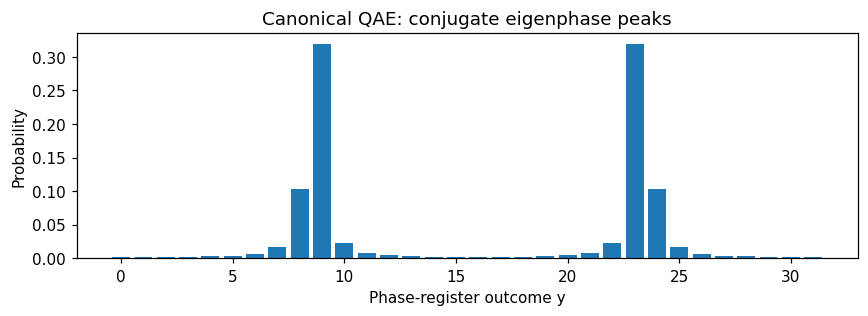

In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(len(phase_probabilities)), phase_probabilities)
ax.set(xlabel='Phase-register outcome y', ylabel='Probability',
       title='Canonical QAE: conjugate eigenphase peaks')
fig.tight_layout()
plt.show()

## 4. Compare repeated-trial estimation errors

Repeat each experiment 200 times, with nine QAE measurements per trial. Fold
conjugate outcomes and use their modal bin. This is a simple estimator for
teaching, **not iterative QAE and not a confidence-interval method**.

For $M=2^m$, each shot costs $M-1$ Grover calls, or $1+2(M-1)$ calls to $A$ or
$A^\dagger$. Give classical Bernoulli sampling the same number of logical
preparation-or-inverse queries. This is a query comparison, not equal elapsed
time: dense matrix simulation, loading, gate synthesis, and hardware noise are
outside these counts. The small discrete table's exact sum remains the strongest
classical baseline.

phase bits | A/A-dagger calls | QAE RMSE | MC RMSE
         2 |               63 | 0.062500 | 0.066127
         3 |              135 | 0.062500 | 0.042007
         4 |              279 | 0.063006 | 0.032153
         5 |              567 | 0.038851 | 0.020739
         6 |             1143 | 0.013491 | 0.014714


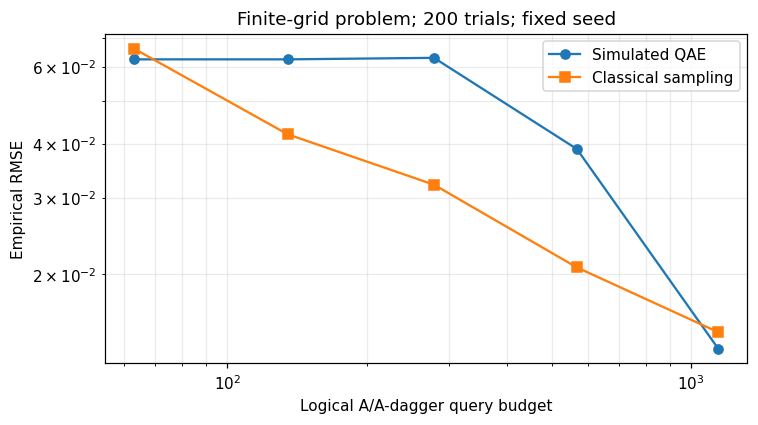

In [6]:
results = benchmark(state, seed=2026, trials=200, shots=9)
print('phase bits | A/A-dagger calls | QAE RMSE | MC RMSE')
for row in results:
    print(f"{row['phase_qubits']:10d} | "
          f"{row['preparation_calls_A_or_Adagger']:16d} | "
          f"{row['qae_rmse']:.6f} | {row['mc_rmse']:.6f}")

budgets = [r['preparation_calls_A_or_Adagger'] for r in results]
fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(budgets, [r['qae_rmse'] for r in results], 'o-', label='Simulated QAE')
ax.loglog(budgets, [r['mc_rmse'] for r in results], 's-', label='Classical sampling')
ax.set(xlabel='Logical A/A-dagger query budget', ylabel='Empirical RMSE',
       title='Finite-grid problem; 200 trials; fixed seed')
ax.grid(True, which='both', alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

The coarse phase grids can give repeated estimates near 0.5 and a plateau in QAE
error. More phase qubits improve resolution, but this short experiment is not a
proof of an asymptotic scaling law. It also does not establish a consistent
advantage over classical sampling. Repeating with other thresholds changes the
alignment between the true amplitude and the phase grid.

## 5. Estimate mean force with the same operations

Replace the indicator by force divided by a known bound. For this positive,
monotone magnetic circuit, the maximum over the modeled rectangular input domain
occurs at maximum current and minimum gap. This supplies an explicit bound without
estimating it from the sample grid. The same bound would need separate justification
for a nonlinear FEMM model or a surrogate.

In [7]:
_, force_upper_bound = MagneticCircuit().field_and_force(1.2, 0.8e-3)
normalized_force = problem['forces_n'].ravel() / force_upper_bound
mean_state = encoded_state(probabilities, normalized_force)
assert np.isclose(np.sum(mean_state[1::2]**2) * force_upper_bound, exact_mean_force)
mean_distribution = qae_distribution(mean_state, phase_qubits=6)
mean_counts = np.random.default_rng(2027).multinomial(9, mean_distribution)
mean_estimate = estimate_from_counts(mean_counts) * force_upper_bound
print(f'Force bound over input rectangle: {force_upper_bound:.6f} N')
print(f'Estimated mean force: {mean_estimate:.6f} N')
print(f'Exact grid mean force: {exact_mean_force:.6f} N')

Force bound over input rectangle: 30.114675 N
Estimated mean force: 15.057338 N
Exact grid mean force: 14.453337 N


## 6. Separate input discretization from estimation error

Increasing phase precision does not refine the input distribution. Enumerate
successively finer classical grids to inspect discretization error. These values
are not additional quantum runs. Because the failure indicator is discontinuous,
its grid-convergence sequence need not be monotone. Even a perfectly estimated
4-by-4 amplitude would differ from the continuous-input failure probability.

In [8]:
print('points/input | grid cases | failure probability | mean force, N')
for points in (4, 8, 16, 32, 64, 128):
    refined = reliability_problem(points_per_input=points)
    print(f'{points:12d} | {points**2:10d} | '
          f'{refined["failure_values"].mean():19.6f} | '
          f'{refined["forces_n"].mean():13.6f}')

points/input | grid cases | failure probability | mean force, N
           4 |         16 |            0.562500 |     14.453337
           8 |         64 |            0.546875 |     14.488036
          16 |        256 |            0.519531 |     14.496750
          32 |       1024 |            0.517578 |     14.498931
          64 |       4096 |            0.517090 |     14.499477
         128 |      16384 |            0.517456 |     14.499613


## Interpretation and next experiment

The implemented result is a verified statevector simulation for failure probability
and mean force on a synthetic finite input grid. It does not validate the simplified
force law against the thesis actuator. The reported estimation errors omit physics
error, uncertainty-model error, and quantum-device noise.

Next, calibrate the response against the book's FEMM C-core model, compare
quadrature and scrambled quasi-Monte Carlo, and investigate an efficient reversible
response evaluator. Translate the small reference into a gate-model SDK before
attempting hardware. See the [research milestones](05_research_plan.md).